In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, classification_report
from xgboost import XGBClassifier
import joblib

In [2]:
train = pd.read_csv("e:/Skill_Dev/Projects/DataScience/CreditCardLeadsPrediction/dataset/train_s3TEQDk.csv")
test = pd.read_csv("E:/Skill_Dev/Projects/DataScience/CreditCardLeadsPrediction/dataset/test_mSzZ8RL.csv")

In [3]:
# saving IDs separately for later final prediction
test_ids = test["ID"]

In [4]:
train.head(5)

,ID,Gender,Age,Region_Code,Occupation,Channel_Code,Vintage,Credit_Product,Avg_Account_Balance,Is_Active,Is_Lead
0,NNVBBKZB,Female,73,RG268,Other,X3,43,No,1045696,No,0
1,IDD62UNG,Female,30,RG277,Salaried,X1,32,No,581988,No,0
2,HD3DSEMC,Female,56,RG268,Self_Employed,X3,26,No,1484315,Yes,0
3,BF3NC7KV,Male,34,RG270,Salaried,X1,19,No,470454,No,0
4,TEASRWXV,Female,30,RG282,Salaried,X1,33,No,886787,No,0


In [5]:
test.head(5)

,ID,Gender,Age,Region_Code,Occupation,Channel_Code,Vintage,Credit_Product,Avg_Account_Balance,Is_Active
0,VBENBARO,Male,29,RG254,Other,X1,25,Yes,742366,No
1,CCMEWNKY,Male,43,RG268,Other,X2,49,NaN,925537,No
2,VK3KGA9M,Male,31,RG270,Salaried,X1,14,No,215949,No
3,TT8RPZVC,Male,29,RG272,Other,X1,33,No,868070,No
4,SHQZEYTZ,Female,29,RG270,Other,X1,19,No,657087,No


In [6]:
train.drop("ID", axis=1, inplace=True)
test.drop("ID", axis=1, inplace=True)

In [7]:
# separating features & target
X = train.drop("Is_Lead", axis=1)
y = train["Is_Lead"]

In [8]:
# handling categorical values using one-hot encoding

X = pd.get_dummies(X, drop_first=True)
test = pd.get_dummies(test, drop_first=True)

In [9]:
# aligning train and test to have same columns
X, test = X.align(test, join="left", axis=1, fill_value=0)

In [10]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [11]:
# XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(len(y_train[y_train==0]) / len(y_train[y_train==1])), # imbalance handling
    random_state=42,
    use_label_encoder=False,
    eval_metric="logloss"
)

In [12]:
xgb_model.fit(X_train, y_train)

E:\Softwares\Installed\Anaconda3\envs\tf-gpu\lib\site-packages\xgboost\core.py:158: UserWarning: [15:07:50] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

In [13]:
# evaluation
y_val_pred = xgb_model.predict(X_val)
y_val_proba = xgb_model.predict_proba(X_val)[:,1]

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("\nClassification Report:\n", classification_report(y_val, y_val_pred))

Accuracy: 0.709919625597721
Recall: 0.7305712815234174
F1 Score: 0.5443911792905082
ROC-AUC: 0.7854996239721198

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.70      0.79     37487
           1       0.43      0.73      0.54     11658

    accuracy                           0.71     49145
   macro avg       0.66      0.72      0.67     49145
weighted avg       0.78      0.71      0.73     49145



In [14]:
joblib.dump(xgb_model, "xgb_credit_leads.pkl")

['xgb_credit_leads.pkl']

In [15]:
loaded_model = joblib.load("xgb_credit_leads.pkl")

test_preds = loaded_model.predict_proba(test)[:, 1]  # probabilities of being a lead

submission = pd.DataFrame({
    "ID": test_ids,
    "Is_Lead": test_preds
})

submission.to_csv("xgb_submission.csv", index=False)
print("\nSubmission file 'xgb_submission.csv' created successfully!")



Submission file 'xgb_submission.csv' created successfully!


In [16]:
chart = pd.read_csv("xgb_submission.csv")

# Convert probabilities to binary
chart["Predicted_Label"] = (chart["Is_Lead"] >= 0.5).astype(int)
# chart["Predicted_Label"] = (chart["Is_Lead"] >= 0.37).astype(int)

# Counting 0 and 1
counts = chart["Predicted_Label"].value_counts()


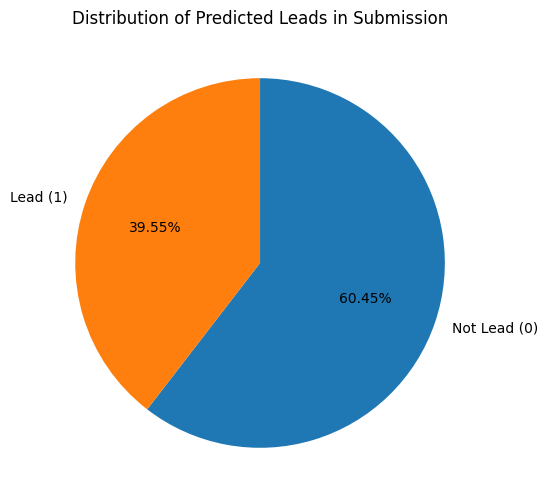

In [17]:
# Pie chart
plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=["Not Lead (0)", "Lead (1)"],
    autopct="%.2f%%",
    startangle=90,
    counterclock=False
)
plt.title("Distribution of Predicted Leads in Submission")
plt.show()

In [18]:
from sklearn.metrics import precision_recall_curve, f1_score

precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

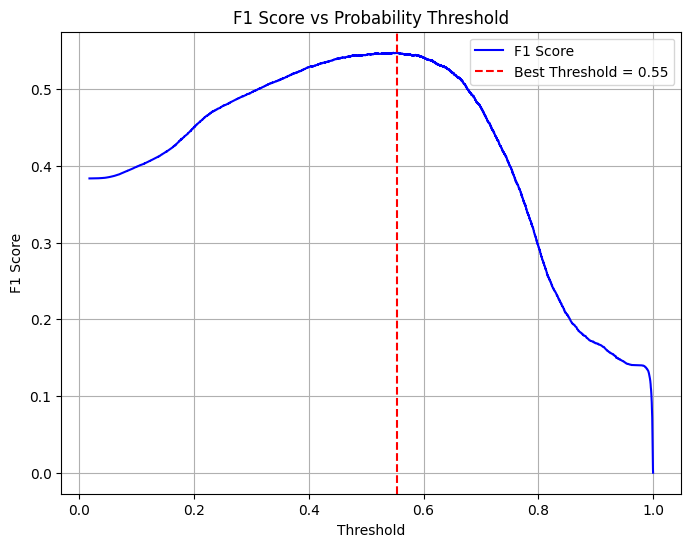

In [19]:
# Plot F1 vs Threshold
plt.figure(figsize=(8,6))
plt.plot(thresholds, f1_scores[:-1], label="F1 Score", color="blue")
plt.axvline(x=best_threshold, color="red", linestyle="--", label=f"Best Threshold = {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Probability Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
print("Best Threshold:", best_threshold)
print("Best F1 Score:", best_f1)

Best Threshold: 0.5544087
Best F1 Score: 0.547182999656932


In [21]:
y_val_pred_opt = (y_val_proba >= best_threshold).astype(int)

print("\n=== Evaluation at Optimal Threshold ===")
print("Accuracy:", accuracy_score(y_val, y_val_pred_opt))
print("Recall:", recall_score(y_val, y_val_pred_opt))
print("F1 Score:", f1_score(y_val, y_val_pred_opt))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))
print("\nClassification Report:\n", classification_report(y_val, y_val_pred_opt))


=== Evaluation at Optimal Threshold ===
Accuracy: 0.7363719605249771
Recall: 0.6714702350317379
F1 Score: 0.5471830001398015
ROC-AUC: 0.7854996239721198

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.76      0.81     37487
           1       0.46      0.67      0.55     11658

    accuracy                           0.74     49145
   macro avg       0.67      0.71      0.68     49145
weighted avg       0.78      0.74      0.75     49145



In [22]:
joblib.dump((xgb_model, best_threshold), "xgb_credit_leads_with_threshold.pkl")

['xgb_credit_leads_with_threshold.pkl']

In [23]:
test_proba = xgb_model.predict_proba(test)[:, 1]
test_preds = (test_proba >= best_threshold).astype(int)  # binary predictions

In [24]:
opt_submission_binary = pd.DataFrame({
    "ID": test_ids,
    "Is_Lead": test_preds
})

opt_submission_binary.to_csv("opt_submission_binary.csv", index=False)
print("Binary submission file saved as opt_submission_binary.csv")

opt_submission_proba = pd.DataFrame({
    "ID": test_ids,
    "Is_Lead": test_proba
})

opt_submission_proba.to_csv("opt_xgb_submission_proba.csv", index=False)
print("Probability submission file saved as opt_xgb_submission_proba.csv")

Binary submission file saved as opt_submission_binary.csv
Probability submission file saved as opt_xgb_submission_proba.csv


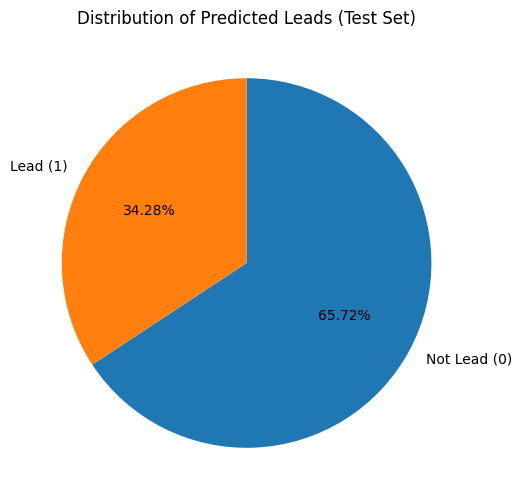

In [25]:
#tell number of leads and non-leads

counts = opt_submission_binary["Is_Lead"].value_counts()

# Plot pie chart
plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=["Not Lead (0)", "Lead (1)"],
    autopct="%.2f%%",
    startangle=90,
    counterclock=False
)
plt.title("Distribution of Predicted Leads (Test Set)")
plt.show()


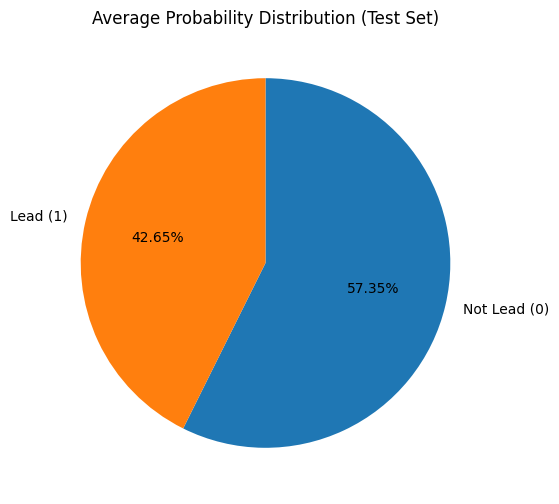

In [26]:
#tells confidence

lead_prob = test_proba.mean()
nonlead_prob = 1 - lead_prob

# Pie chart
plt.figure(figsize=(6,6))
plt.pie(
    [nonlead_prob, lead_prob],
    labels=["Not Lead (0)", "Lead (1)"],
    autopct="%.2f%%",
    startangle=90,
    counterclock=False
)
plt.title("Average Probability Distribution (Test Set)")
plt.show()